# Week 3 — Task 3.2
## Fashion Image Classification using TensorFlow/Keras

### Problem Statement

The goal of this project is to build a computer vision classification model
that can identify different categories of fashion items from grayscale images.

The model will classify each image into one of ten Fashion-MNIST categories.

The project includes data inspection, preprocessing, baseline modeling,
TensorFlow/Keras model training, evaluation, error analysis, and inference
on unseen samples.

Import Libraries

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras import datasets, layers, models
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


Load Dataset

In [2]:
(x_train, y_train), (x_test, y_test) = datasets.fashion_mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


Define Class Names

In [3]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Number of classes:", len(class_names))

Number of classes: 10


Missing values

In [4]:
print("Missing values in training images:", np.isnan(x_train).sum())
print("Missing values in test images:", np.isnan(x_test).sum())

print("Missing values in training labels:", np.isnan(y_train).sum())
print("Missing values in test labels:", np.isnan(y_test).sum())

Missing values in training images: 0
Missing values in test images: 0
Missing values in training labels: 0
Missing values in test labels: 0


Class Distribution

In [5]:
unique_classes, class_counts = np.unique(
    y_train,
    return_counts=True
)

class_distribution = pd.DataFrame({
    "Class": [class_names[i] for i in unique_classes],
    "Count": class_counts
})

class_distribution

,Class,Count
0,T-shirt/top,6000
1,Trouser,6000
2,Pullover,6000
3,Dress,6000
4,Coat,6000
5,Sandal,6000
6,Shirt,6000
7,Sneaker,6000
8,Bag,6000
9,Ankle boot,6000


Plot

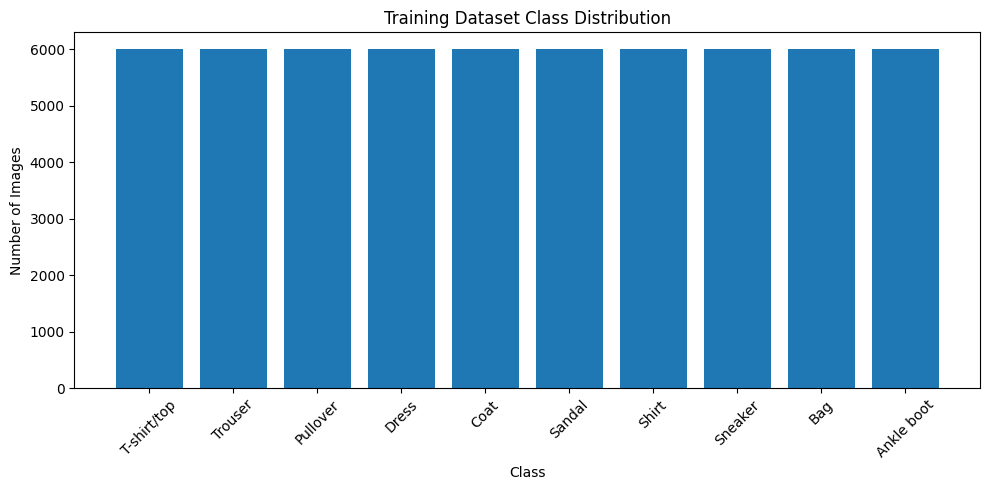

In [6]:
plt.figure(figsize=(10, 5))

plt.bar(
    class_distribution["Class"],
    class_distribution["Count"]
)

plt.title("Training Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Class Distribution Observation

The Fashion-MNIST training dataset contains ten image classes.
The class distribution is relatively balanced, with each class having
a similar number of training examples. Therefore, no major class
imbalance is observed.

Duplicate Check

In [7]:
unique_images = np.unique(
    x_train.reshape(x_train.shape[0], -1),
    axis=0
)

duplicate_count = len(x_train) - len(unique_images)

print("Total training images:", len(x_train))
print("Unique training images:", len(unique_images))
print("Duplicate images:", duplicate_count)

Total training images: 60000
Unique training images: 60000
Duplicate images: 0


 Visual Dataset Inspection

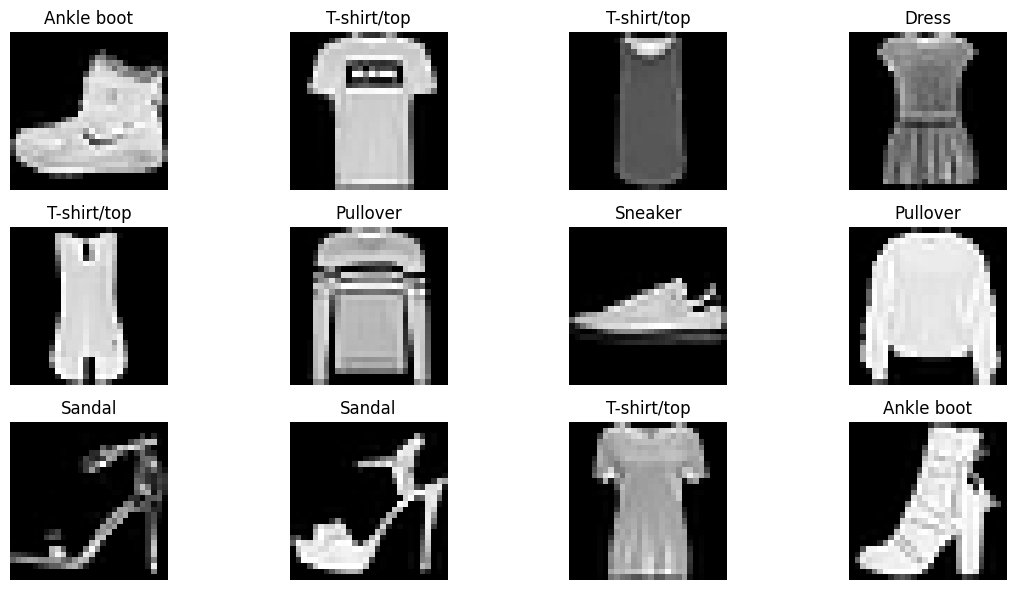

In [8]:
plt.figure(figsize=(12, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

Label Quality Check

In [9]:
print("Minimum label:", y_train.min())
print("Maximum label:", y_train.max())

invalid_labels = np.sum(
    (y_train < 0) | (y_train > 9)
)

print("Invalid labels:", invalid_labels)

Minimum label: 0
Maximum label: 9
Invalid labels: 0


Preprocessing

In [10]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


Add Channel Dimension

In [11]:
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


Train/Validation Split

In [12]:
validation_size = 5000

x_val = x_train[-validation_size:]
y_val = y_train[-validation_size:]

x_train_final = x_train[:-validation_size]
y_train_final = y_train[:-validation_size]

print("Training:", x_train_final.shape)
print("Validation:", x_val.shape)
print("Testing:", x_test.shape)

Training: (55000, 28, 28, 1)
Validation: (5000, 28, 28, 1)
Testing: (10000, 28, 28, 1)


Baseline Model

In [13]:
baseline_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Train baseline

In [14]:
baseline_history = baseline_model.fit(
    x_train_final,
    y_train_final,
    epochs=5,
    batch_size=64,
    validation_data=(x_val, y_val),
    verbose=1
)

Epoch 1/5
860/860 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8189 - loss: 0.5253 - val_accuracy: 0.8530 - val_loss: 0.4194
Epoch 2/5
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8619 - loss: 0.3909 - val_accuracy: 0.8646 - val_loss: 0.3657
Epoch 3/5
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8742 - loss: 0.3495 - val_accuracy: 0.8710 - val_loss: 0.3543
Epoch 4/5
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8829 - loss: 0.3208 - val_accuracy: 0.8764 - val_loss: 0.3392
Epoch 5/5
860/860 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8903 - loss: 0.3022 - val_accuracy: 0.8646 - val_loss: 0.3831


Baseline evaluation

In [15]:
baseline_loss, baseline_accuracy = baseline_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Baseline Test Accuracy: {baseline_accuracy * 100:.2f}%")

Baseline Test Accuracy: 85.37%


Main CNN Model

In [16]:
cnn_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax")
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 896,906 (3.42 MB)

 Trainable params: 896,906 (3.42 MB)

 Non-trainable params: 0 (0.00 B)

Compile

In [17]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Train CNN

In [18]:
cnn_history = cnn_model.fit(
    x_train_final,
    y_train_final,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val),
    verbose=1
)

Epoch 1/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 106s 121ms/step - accuracy: 0.8292 - loss: 0.4794 - val_accuracy: 0.8862 - val_loss: 0.3103
Epoch 2/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 105s 122ms/step - accuracy: 0.8907 - loss: 0.3030 - val_accuracy: 0.9028 - val_loss: 0.2632
Epoch 3/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 118s 137ms/step - accuracy: 0.9077 - loss: 0.2545 - val_accuracy: 0.9130 - val_loss: 0.2337
Epoch 4/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 122s 141ms/step - accuracy: 0.9187 - loss: 0.2236 - val_accuracy: 0.9104 - val_loss: 0.2394
Epoch 5/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 128s 126ms/step - accuracy: 0.9266 - loss: 0.1985 - val_accuracy: 0.9248 - val_loss: 0.2145
Epoch 6/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 165s 153ms/step - accuracy: 0.9329 - loss: 0.1808 - val_accuracy: 0.9234 - val_loss: 0.2264
Epoch 7/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 130s 139ms/step - accuracy: 0.9413 - loss: 0.1588 - val_accuracy: 0.9210 - val_loss: 0.2249
Epoch 8/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 102s 118ms/step - accuracy: 0.9471 -

Training Curves

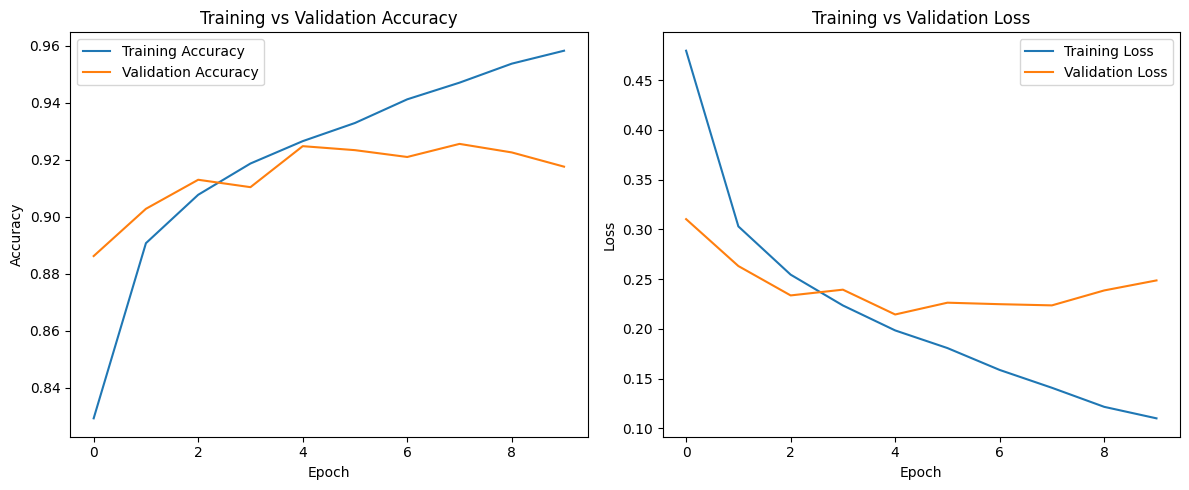

In [19]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    cnn_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    cnn_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    cnn_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    cnn_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Final Model Evaluation

In [20]:
test_loss, test_accuracy = cnn_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.2589
Test Accuracy: 91.57%


Baseline vs CNN

In [21]:
print(
    f"Baseline Accuracy: "
    f"{baseline_accuracy * 100:.2f}%"
)

print(
    f"CNN Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

improvement = (
    test_accuracy - baseline_accuracy
) * 100

print(
    f"Accuracy improvement: "
    f"{improvement:.2f} percentage points"
)

Baseline Accuracy: 85.37%
CNN Accuracy: 91.57%
Accuracy improvement: 6.20 percentage points


Classification Report

In [22]:
y_prob = cnn_model.predict(
    x_test,
    verbose=0
)

y_pred = np.argmax(y_prob, axis=1)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.90      0.80      0.85      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.91      0.82      0.86      1000
       Dress       0.92      0.93      0.92      1000
        Coat       0.87      0.88      0.88      1000
      Sandal       0.99      0.97      0.98      1000
       Shirt       0.70      0.84      0.76      1000
     Sneaker       0.95      0.98      0.97      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.98      0.96      0.97      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



Confusion Matrix

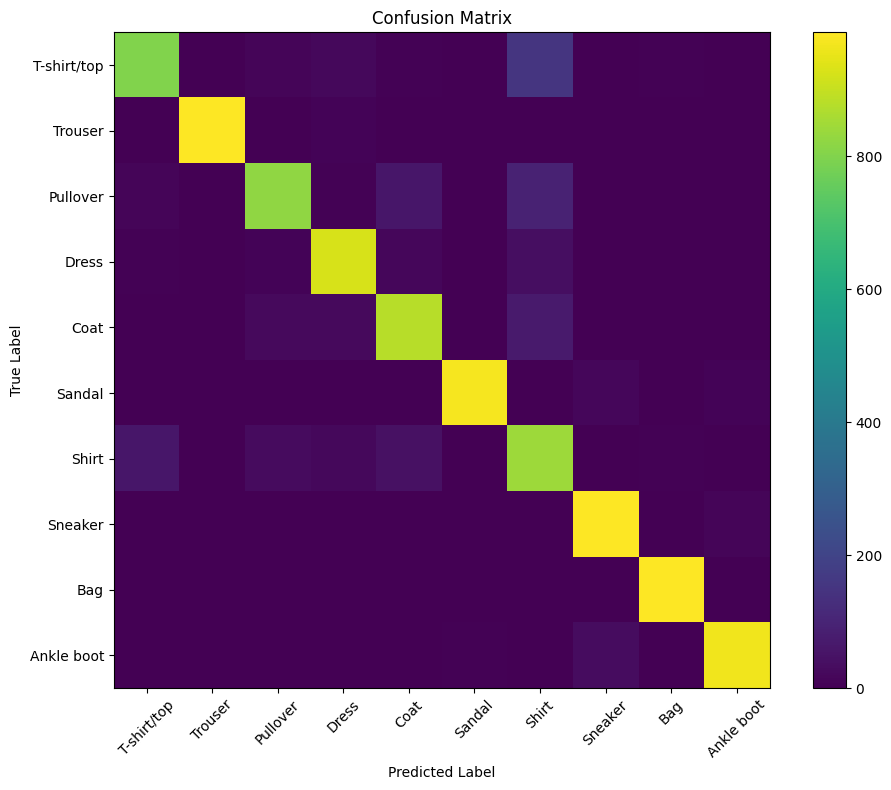

In [23]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    range(10),
    class_names,
    rotation=45
)

plt.yticks(
    range(10),
    class_names
)

plt.colorbar()

plt.tight_layout()
plt.show()

Error Analysis

In [24]:
misclassified_indices = np.where(
    y_pred != y_test
)[0]

print(
    "Total misclassified images:",
    len(misclassified_indices)
)

print(
    "Misclassification rate:",
    f"{len(misclassified_indices) / len(y_test) * 100:.2f}%"
)

Total misclassified images: 843
Misclassification rate: 8.43%


Show Misclassified Images


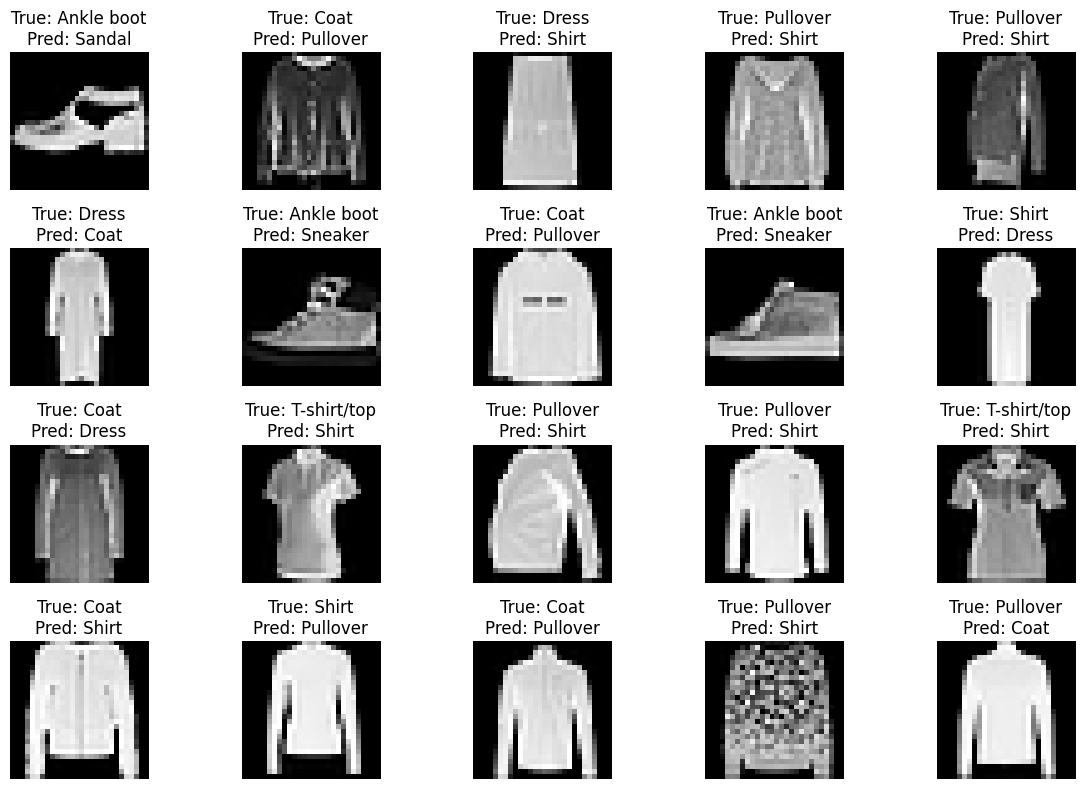

In [25]:
plt.figure(figsize=(12, 8))

for i, index in enumerate(misclassified_indices[:20]):

    plt.subplot(4, 5, i + 1)

    plt.imshow(
        x_test[index].squeeze(),
        cmap="gray"
    )

    plt.title(
        f"True: {class_names[y_test[index]]}\n"
        f"Pred: {class_names[y_pred[index]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

Find Common Error Pairs

In [26]:
error_pairs = pd.DataFrame({
    "Actual": [
        class_names[y_test[i]]
        for i in misclassified_indices
    ],
    "Predicted": [
        class_names[y_pred[i]]
        for i in misclassified_indices
    ]
})

error_counts = (
    error_pairs
    .value_counts()
    .reset_index(name="Count")
)

error_counts.head(10)

,Actual,Predicted,Count
0,T-shirt/top,Shirt,154
1,Pullover,Shirt,93
2,Coat,Shirt,73
3,Shirt,T-shirt/top,61
4,Pullover,Coat,61
5,Shirt,Coat,43
6,Dress,Shirt,37
7,Ankle boot,Sneaker,31
8,Shirt,Pullover,30
9,Coat,Dress,24


## Error Analysis

The model produced some incorrect predictions on the test dataset.
The misclassified examples were inspected visually to identify common
patterns.

Some errors occur between visually similar clothing categories. For
example, categories with similar shapes or appearance can be difficult
for the model to distinguish from low-resolution grayscale images.

The confusion matrix and misclassified examples were used to identify
these error patterns rather than relying only on the overall accuracy.

Inference on an Unseen Sample

In [27]:
def predict_fashion_image(model, image):

    image_batch = np.expand_dims(image, axis=0)

    probabilities = model.predict(
        image_batch,
        verbose=0
    )[0]

    predicted_class = np.argmax(probabilities)
    confidence = probabilities[predicted_class]

    return (
        class_names[predicted_class],
        confidence
    )

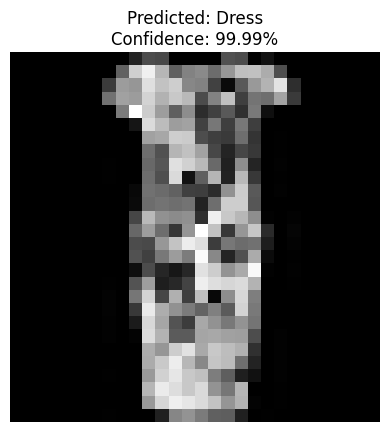

Actual: Dress
Predicted: Dress
Confidence: 99.99%


In [28]:
sample_index = 100

image = x_test[sample_index]

predicted_class, confidence = predict_fashion_image(
    cnn_model,
    image
)

plt.imshow(
    image.squeeze(),
    cmap="gray"
)

plt.title(
    f"Predicted: {predicted_class}\n"
    f"Confidence: {confidence * 100:.2f}%"
)

plt.axis("off")
plt.show()

print("Actual:", class_names[y_test[sample_index]])
print("Predicted:", predicted_class)
print(f"Confidence: {confidence * 100:.2f}%")

Save Model

In [29]:
cnn_model.save(
    "fashion_mnist_classifier.keras"
)

print("Model saved successfully.")

Model saved successfully.


Load Model Again

In [30]:
loaded_model = tf.keras.models.load_model(
    "fashion_mnist_classifier.keras"
)

print("Model loaded successfully.")

Model loaded successfully.


In [31]:
loaded_loss, loaded_accuracy = loaded_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(
    f"Loaded Model Accuracy: "
    f"{loaded_accuracy * 100:.2f}%"
)

Loaded Model Accuracy: 91.57%


## Limitations

- Fashion-MNIST contains small 28×28 grayscale images, so the model is
  designed for a relatively simple image-classification problem.
- Visually similar categories can still be difficult to distinguish.
- The dataset does not represent real-world clothing images with
  different backgrounds, lighting conditions, camera angles, or image
  quality.
- The model's performance on Fashion-MNIST should not be assumed to
  represent performance on real-world fashion images.

## Possible Future Improvements

Possible improvements include:

1. Applying data augmentation.
2. Experimenting with different CNN architectures.
3. Using batch normalization.
4. Tuning learning rate and batch size.
5. Using transfer learning on a more realistic image dataset.
6. Collecting a larger and more diverse real-world dataset.

## Conclusion

A TensorFlow/Keras CNN model was developed for Fashion-MNIST image
classification. The project included dataset inspection, preprocessing,
baseline modeling, CNN training, evaluation, confusion-matrix analysis,
misclassification analysis, and reproducible inference.

The CNN model was compared with a simpler baseline model using the same
test dataset. The analysis showed how model architecture affects
classification performance and also highlighted errors between visually
similar classes.

The final trained model was saved in Keras format for later use.